CUSTOMER SEGMENT PERFORMANCE AND SLA EXPOSURE ANALYSIS

DATASET INFORMATION
------------------------------------------------------------------------------------------
Source file: C:\Users\hp\Analysis in Global Supply Chain Operations\data\processed\delivery_gap_analysis.csv
Dataset rows: 180,519
Dataset columns: 39

CUSTOMER SEGMENT CATEGORIES
------------------------------------------------------------------------------------------
Identified segments: 3
- Consumer
- Corporate
- Home Office

DELIVERY ELIGIBILITY SUMMARY
------------------------------------------------------------------------------------------
Total source records: 180,519
Cancelled records excluded: 7,754
Records with invalid delivery durations: 0
Records with missing customer segment: 0
Eligible customer-segment records: 172,765
Zero scheduled duration Same Day shipments are retained.

CUSTOMER SEGMENT PERFORMANCE COMPARISON
------------------------------------------------------------------------------------------
C

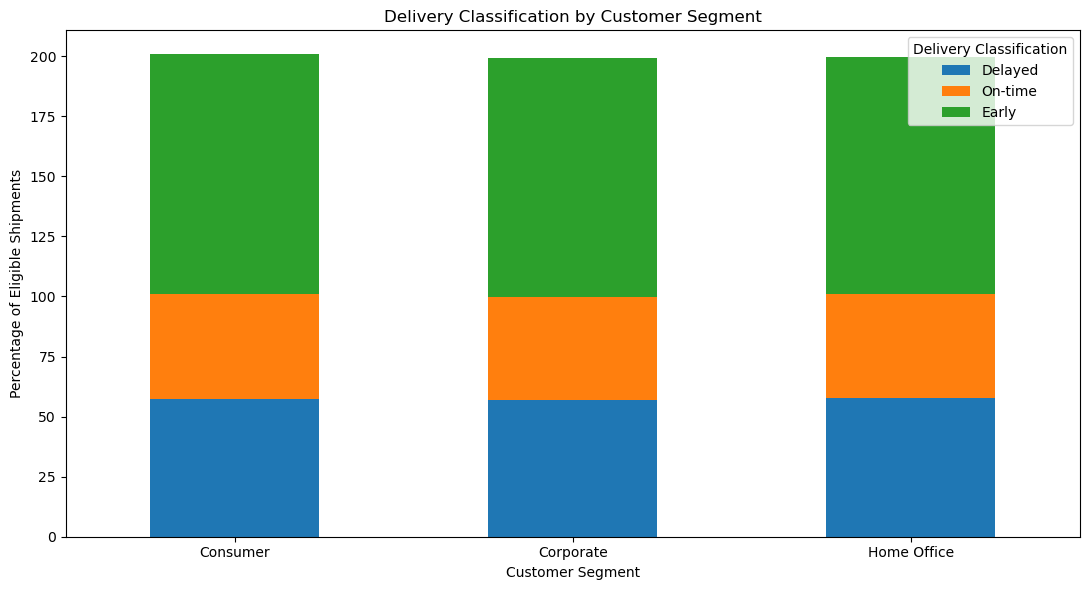

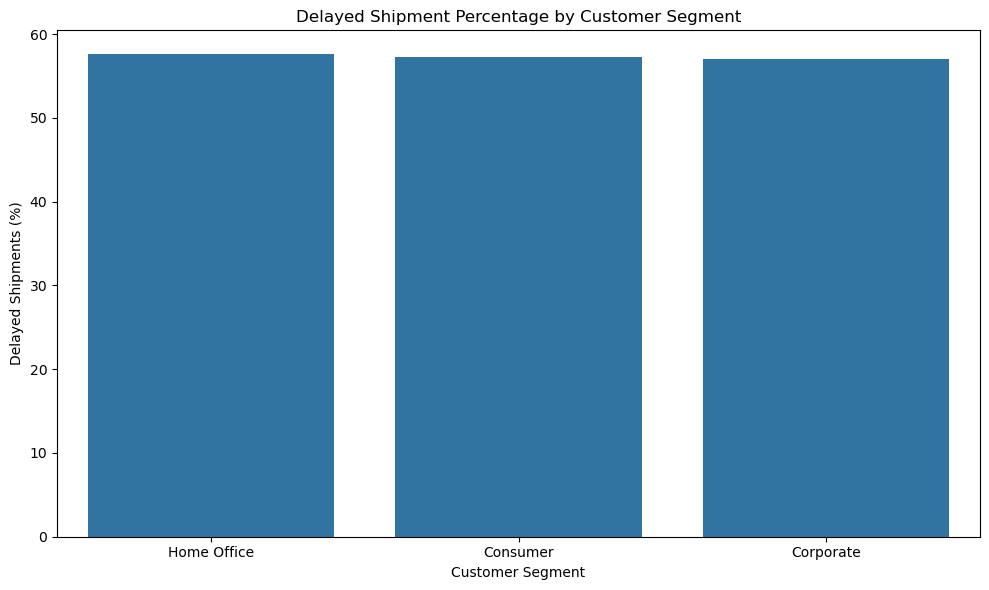

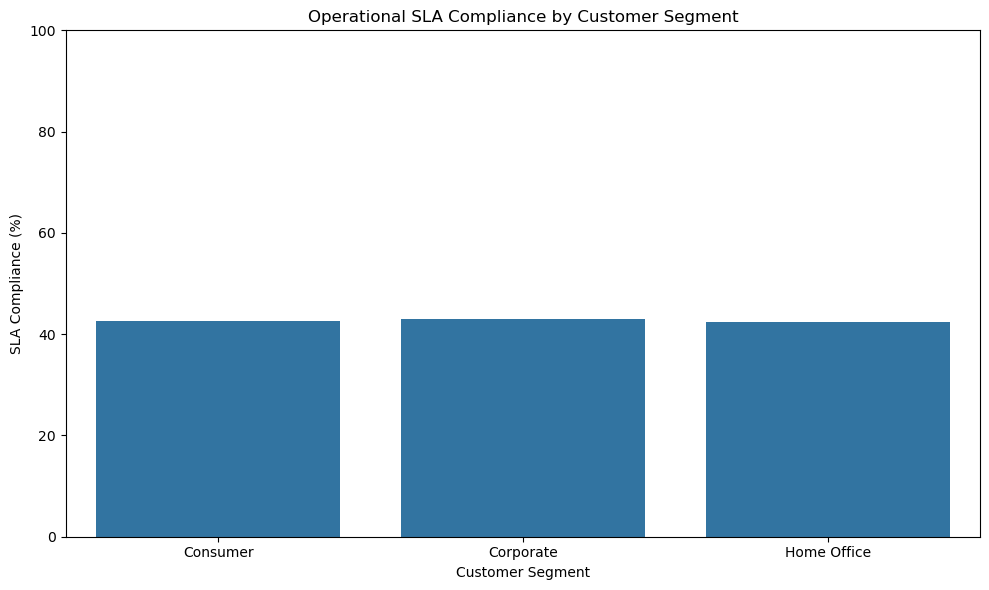

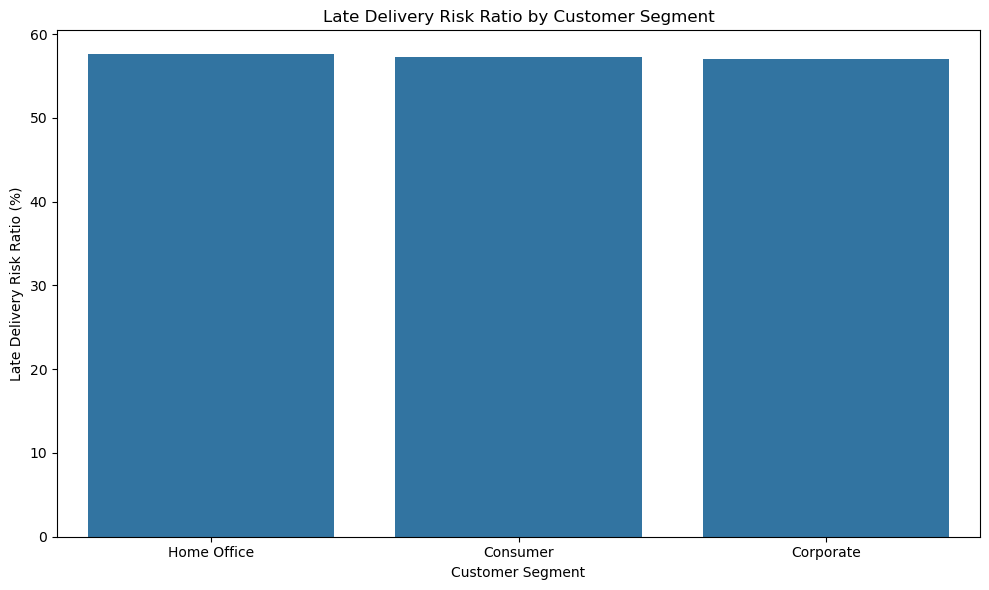

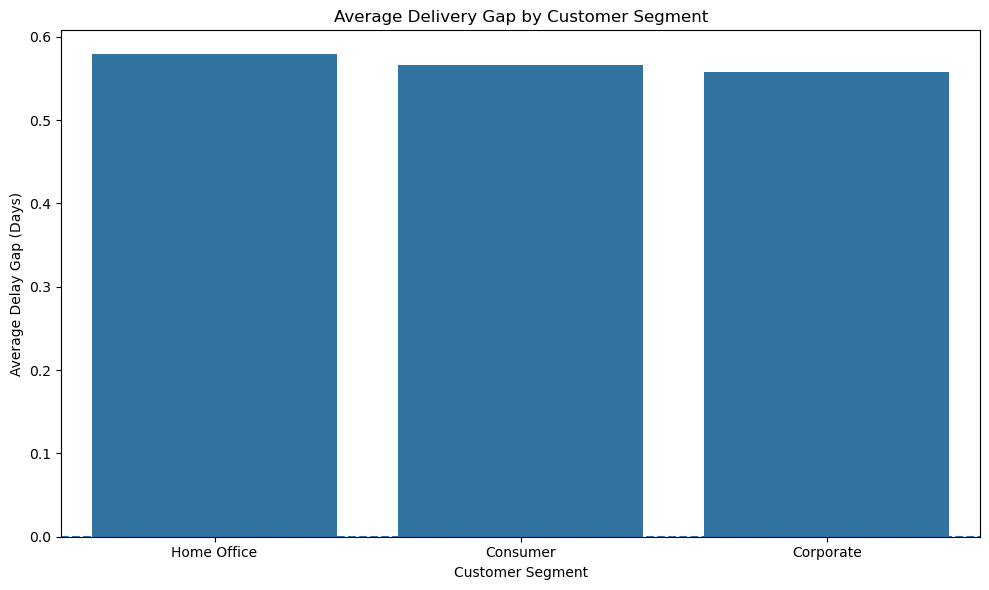

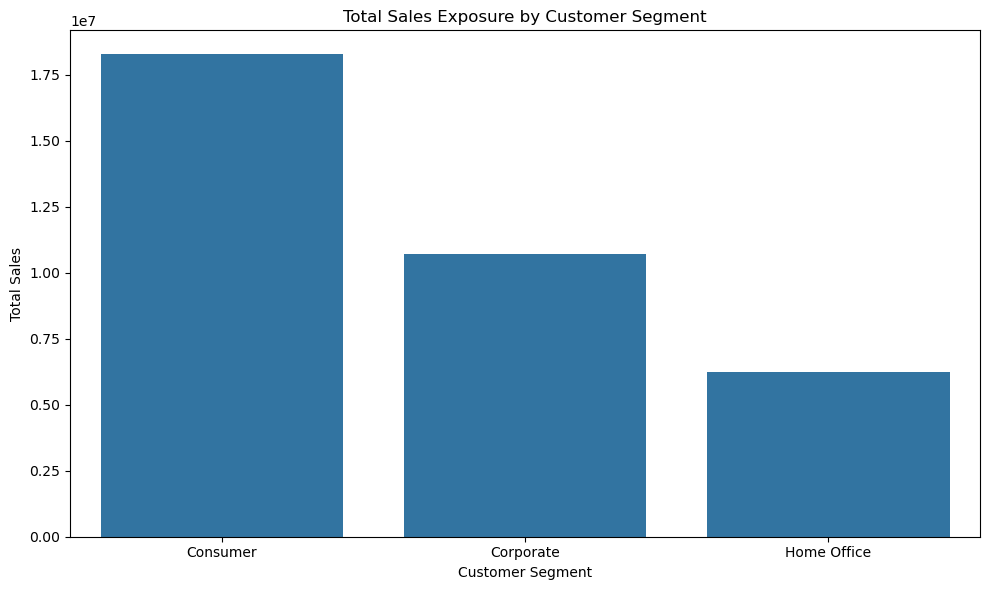

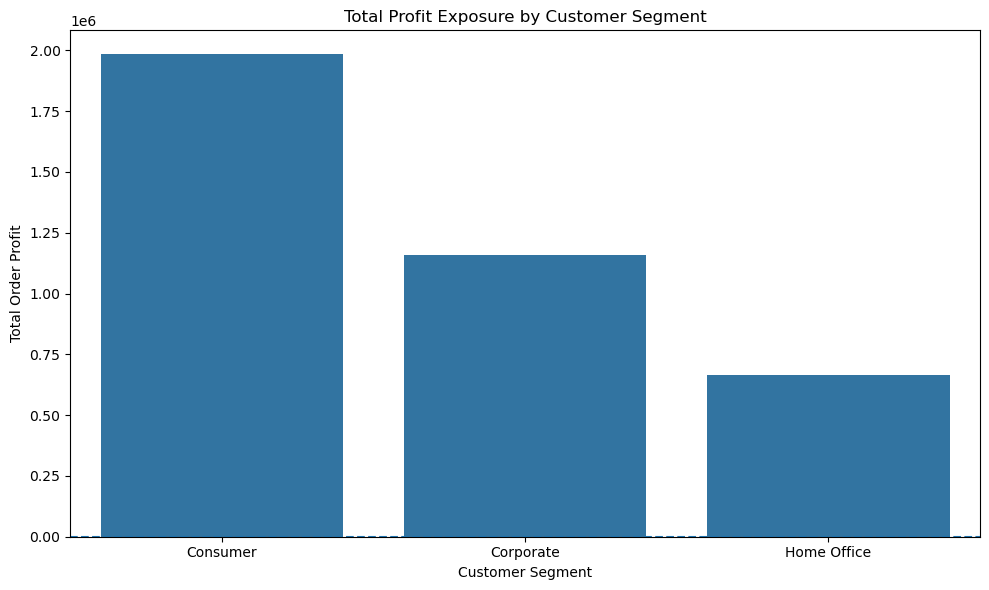


CUSTOMER SEGMENT ANALYSIS VALIDATION
------------------------------------------------------------------------------------------
                                    Validation Check Status                                                    Details
                   Input dataset loaded successfully   PASS                                           Records: 180,519
               Required analytical columns available   PASS                                 All required columns found
                        Customer segments identified   PASS                                                Segments: 3
            Eligible records contain valid durations   PASS                                  Eligible records: 172,765
        Eligible records exclude cancelled shipments   PASS                            No cancelled shipments included
       Eligible records have customer segment values   PASS              No missing segment values in eligible records
                       Delivery gap fo

In [6]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

warnings.filterwarnings("ignore")

# CUSTOMER SEGMENT PERFORMANCE AND SLA EXPOSURE ANALYSIS

PROJECT_ROOT = r"C:\Users\hp\Analysis in Global Supply Chain Operations"
INPUT_FILE = os.path.join(PROJECT_ROOT, "data", "processed", "delivery_gap_analysis.csv")

TABLE_DIR = os.path.join(PROJECT_ROOT, "outputs", "tables")
REPORT_DIR = os.path.join(PROJECT_ROOT, "outputs", "reports")
FIGURE_DIR = os.path.join(PROJECT_ROOT, "outputs", "figures")

for directory in [TABLE_DIR, REPORT_DIR, FIGURE_DIR]:
    os.makedirs(directory, exist_ok=True)

print("=" * 90)
print("CUSTOMER SEGMENT PERFORMANCE AND SLA EXPOSURE ANALYSIS")
print("=" * 90)

# LOAD AND INSPECT ANALYTICAL DATASET

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(f"Input dataset not found: {INPUT_FILE}")

df = pd.read_csv(INPUT_FILE, low_memory=False)

print("\nDATASET INFORMATION")
print("-" * 90)
print(f"Source file: {INPUT_FILE}")
print(f"Dataset rows: {len(df):,}")
print(f"Dataset columns: {len(df.columns):,}")

required_columns = [
    "Customer Segment",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Late_delivery_risk",
    "Sales",
    "Order Profit Per Order"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# STANDARDIZE CUSTOMER SEGMENT AND DELIVERY FIELDS

data = df.copy()

data["Customer Segment"] = (
    data["Customer Segment"]
    .astype("string")
    .str.strip()
)

data["Delivery Status"] = (
    data["Delivery Status"]
    .astype("string")
    .str.strip()
)

data["Days for shipping (real)"] = pd.to_numeric(
    data["Days for shipping (real)"], errors="coerce"
)

data["Days for shipment (scheduled)"] = pd.to_numeric(
    data["Days for shipment (scheduled)"], errors="coerce"
)

data["Late_delivery_risk"] = pd.to_numeric(
    data["Late_delivery_risk"], errors="coerce"
)

data["Sales"] = pd.to_numeric(data["Sales"], errors="coerce")
data["Order Profit Per Order"] = pd.to_numeric(
    data["Order Profit Per Order"], errors="coerce"
)

data["Delivery Status Normalized"] = (
    data["Delivery Status"].str.lower()
)

# IDENTIFY CUSTOMER SEGMENT CATEGORIES

print("\nCUSTOMER SEGMENT CATEGORIES")
print("-" * 90)

segment_categories = sorted(
    data["Customer Segment"].dropna().unique().tolist()
)

print(f"Identified segments: {len(segment_categories)}")

for segment in segment_categories:
    print(f"- {segment}")

expected_segments = {"Consumer", "Corporate", "Home Office"}

# PREPARE ELIGIBLE DELIVERY RECORDS

actual_col = "Days for shipping (real)"
scheduled_col = "Days for shipment (scheduled)"

data["Delay Gap"] = data[actual_col] - data[scheduled_col]

cancelled_mask = (
    data["Delivery Status Normalized"].eq("shipping canceled")
)

valid_duration_mask = (
    data[actual_col].notna()
    & data[scheduled_col].notna()
    & data[actual_col].ge(0)
    & data[scheduled_col].ge(0)
)

valid_segment_mask = (
    data["Customer Segment"].notna()
    & data["Customer Segment"].ne("")
)

eligible_mask = (
    ~cancelled_mask
    & valid_duration_mask
    & valid_segment_mask
)

eligible = data.loc[eligible_mask].copy()

eligible["Delivery Classification"] = np.select(
    [
        eligible["Delay Gap"] > 0,
        eligible["Delay Gap"] == 0,
        eligible["Delay Gap"] < 0
    ],
    [
        "Delayed",
        "On-time",
        "Early"
    ],
    default="Invalid"
)

eligible["SLA Compliant"] = (
    eligible["Delay Gap"] <= 0
)

eligible["Late Risk Valid"] = eligible["Late_delivery_risk"].isin([0, 1])

print("\nDELIVERY ELIGIBILITY SUMMARY")
print("-" * 90)
print(f"Total source records: {len(data):,}")
print(f"Cancelled records excluded: {int(cancelled_mask.sum()):,}")
print(f"Records with invalid delivery durations: {int((~valid_duration_mask).sum()):,}")
print(f"Records with missing customer segment: {int((~valid_segment_mask).sum()):,}")
print(f"Eligible customer-segment records: {len(eligible):,}")
print("Zero scheduled duration Same Day shipments are retained.")

if eligible.empty:
    raise ValueError("No eligible customer-segment delivery records are available.")

# CALCULATE SHIPMENT COUNTS AND SEGMENT-WISE DELIVERY PERFORMANCE

segment_rows = []

for segment in segment_categories:

    group = eligible.loc[
        eligible["Customer Segment"] == segment
    ].copy()

    total = len(group)

    delayed_count = int(
        (group["Delivery Classification"] == "Delayed").sum()
    )

    on_time_count = int(
        (group["Delivery Classification"] == "On-time").sum()
    )

    early_count = int(
        (group["Delivery Classification"] == "Early").sum()
    )

    delayed_pct = (
        delayed_count / total * 100 if total else np.nan
    )

    on_time_pct = (
        on_time_count / total * 100 if total else np.nan
    )

    early_pct = (
        early_count / total * 100 if total else np.nan
    )

    average_gap = group["Delay Gap"].mean()
    median_gap = group["Delay Gap"].median()

    delayed_records = group.loc[
        group["Delivery Classification"] == "Delayed",
        "Delay Gap"
    ]

    average_delay_among_delayed = (
        delayed_records.mean()
        if len(delayed_records) else 0.0
    )

    valid_risk = group.loc[
        group["Late Risk Valid"], "Late_delivery_risk"
    ]

    late_risk_ratio = (
        valid_risk.mean() * 100
        if len(valid_risk) else np.nan
    )

    sla_compliance = (
        group["SLA Compliant"].mean() * 100
    )

    segment_rows.append({
        "Customer Segment": segment,
        "Shipment Count": total,
        "Delayed Count": delayed_count,
        "On-time Count": on_time_count,
        "Early Count": early_count,
        "Delayed Percentage": delayed_pct,
        "On-time Delivery Percentage": on_time_pct,
        "Early Delivery Percentage": early_pct,
        "Average Delay Gap (Days)": average_gap,
        "Median Delay Gap (Days)": median_gap,
        "Average Delay Among Delayed Shipments (Days)": average_delay_among_delayed,
        "Late Delivery Risk Ratio (%)": late_risk_ratio,
        "Valid Late Risk Records": len(valid_risk),
        "SLA Compliance (%)": sla_compliance
    })

segment_performance = pd.DataFrame(segment_rows)

segment_performance = segment_performance.sort_values(
    "Delayed Percentage",
    ascending=False
).reset_index(drop=True)

print("\nCUSTOMER SEGMENT PERFORMANCE COMPARISON")
print("-" * 90)
print(segment_performance.round(3).to_string(index=False))

# ANALYZE CONSUMER, CORPORATE AND HOME OFFICE SEGMENTS

print("\nINDIVIDUAL CUSTOMER SEGMENT ANALYSIS")
print("-" * 90)

individual_segment_reports = []

for segment in ["Consumer", "Corporate", "Home Office"]:

    group = eligible.loc[
        eligible["Customer Segment"] == segment
    ]

    if group.empty:
        print(f"\n{segment}: No eligible records available.")
        continue

    delayed_count = int(
        (group["Delivery Classification"] == "Delayed").sum()
    )

    on_time_count = int(
        (group["Delivery Classification"] == "On-time").sum()
    )

    early_count = int(
        (group["Delivery Classification"] == "Early").sum()
    )

    report = {
        "Customer Segment": segment,
        "Shipment Count": len(group),
        "Delayed Shipments": delayed_count,
        "On-time Shipments": on_time_count,
        "Early Shipments": early_count,
        "Delayed Percentage": delayed_count / len(group) * 100,
        "On-time Percentage": on_time_count / len(group) * 100,
        "Average Delay Gap (Days)": group["Delay Gap"].mean(),
        "Late Delivery Risk Ratio (%)": (
            group.loc[group["Late Risk Valid"], "Late_delivery_risk"].mean() * 100
            if group["Late Risk Valid"].any() else np.nan
        ),
        "SLA Compliance (%)": group["SLA Compliant"].mean() * 100
    }

    individual_segment_reports.append(report)

    print(f"\n{segment.upper()}")
    print("-" * 60)

    for key, value in report.items():
        if key != "Customer Segment":
            if pd.notna(value):
                print(f"{key}: {value:,.3f}")
            else:
                print(f"{key}: Not available")

individual_segment_report = pd.DataFrame(
    individual_segment_reports
)

# COMPARE CUSTOMER SEGMENT DELIVERY PERFORMANCE

classification_counts = (
    eligible.groupby(
        ["Customer Segment", "Delivery Classification"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for classification in ["Delayed", "On-time", "Early"]:
    if classification not in classification_counts.columns:
        classification_counts[classification] = 0

classification_counts = classification_counts[
    ["Customer Segment", "Delayed", "On-time", "Early"]
]

classification_percentages = classification_counts.copy()

for classification in ["Delayed", "On-time", "Early"]:
    classification_percentages[classification] = (
        classification_percentages[classification]
        / classification_percentages[
            ["Delayed", "On-time", "Early"]
        ].sum(axis=1).replace(0, np.nan)
        * 100
    )

# DEFINE OPERATIONAL SLA PROXY

print("\nOPERATIONAL SLA DEFINITION")
print("-" * 90)
print("Operational SLA proxy: Actual shipping duration <= Scheduled shipping duration.")
print("SLA compliant: Delay Gap <= 0 days.")
print("SLA non-compliant: Delay Gap > 0 days.")
print("This is an analytical proxy based on available shipping-duration fields.")
print("It is not a contractual customer-specific SLA.")

eligible["SLA Status"] = np.where(
    eligible["SLA Compliant"],
    "SLA Compliant",
    "SLA Breach"
)

sla_exposure = (
    eligible.groupby("Customer Segment")
    .agg(
        Shipment_Count=("SLA Compliant", "size"),
        SLA_Compliant_Count=("SLA Compliant", "sum"),
        SLA_Breach_Count=("SLA Compliant", lambda x: int((~x).sum()))
    )
    .reset_index()
)

sla_exposure["SLA Compliance (%)"] = (
    sla_exposure["SLA_Compliant_Count"]
    / sla_exposure["Shipment_Count"] * 100
)

sla_exposure["SLA Breach Percentage (%)"] = (
    sla_exposure["SLA_Breach_Count"]
    / sla_exposure["Shipment_Count"] * 100
)

# IDENTIFY HIGH-RISK CUSTOMER SEGMENTS

valid_segment_delay_rates = segment_performance[
    "Delayed Percentage"
].dropna()

if len(valid_segment_delay_rates):
    high_risk_threshold = float(
        valid_segment_delay_rates.quantile(0.75)
    )
else:
    high_risk_threshold = np.nan

segment_performance["High Risk Segment"] = (
    segment_performance["Delayed Percentage"] >= high_risk_threshold
    if pd.notna(high_risk_threshold)
    else False
)

segment_performance["Risk Assessment Threshold (%)"] = high_risk_threshold

high_risk_segments = segment_performance.loc[
    segment_performance["High Risk Segment"]
].copy()

print("\nHIGH-RISK CUSTOMER SEGMENTS")
print("-" * 90)
print(
    f"Relative high-risk threshold (75th percentile): "
    f"{high_risk_threshold:.3f}%"
    if pd.notna(high_risk_threshold)
    else "Relative high-risk threshold: Not available"
)

if high_risk_segments.empty:
    print("No customer segment exceeded the relative high-risk threshold.")
else:
    print(
        high_risk_segments[
            [
                "Customer Segment",
                "Shipment Count",
                "Delayed Percentage",
                "Late Delivery Risk Ratio (%)",
                "SLA Compliance (%)"
            ]
        ].round(3).to_string(index=False)
    )

# ANALYZE CORPORATE CUSTOMER EXPOSURE

corporate_records = eligible.loc[
    eligible["Customer Segment"] == "Corporate"
].copy()

corporate_total = len(corporate_records)

corporate_delayed = int(
    (corporate_records["Delivery Classification"] == "Delayed").sum()
)

corporate_sla_breaches = int(
    (~corporate_records["SLA Compliant"]).sum()
)

corporate_risk_records = corporate_records.loc[
    corporate_records["Late Risk Valid"]
]

corporate_exposure = pd.DataFrame([{
    "Customer Segment": "Corporate",
    "Eligible Shipments": corporate_total,
    "Delayed Shipments": corporate_delayed,
    "Delayed Percentage (%)": (
        corporate_delayed / corporate_total * 100
        if corporate_total else np.nan
    ),
    "SLA Breach Count": corporate_sla_breaches,
    "SLA Breach Percentage (%)": (
        corporate_sla_breaches / corporate_total * 100
        if corporate_total else np.nan
    ),
    "Average Delay Gap (Days)": (
        corporate_records["Delay Gap"].mean()
        if corporate_total else np.nan
    ),
    "Late Delivery Risk Ratio (%)": (
        corporate_risk_records["Late_delivery_risk"].mean() * 100
        if len(corporate_risk_records) else np.nan
    ),
    "Share of Eligible Shipments (%)": (
        corporate_total / len(eligible) * 100
    )
}])

print("\nCORPORATE CUSTOMER EXPOSURE")
print("-" * 90)

if corporate_total:
    print(corporate_exposure.round(3).to_string(index=False))
else:
    print("No eligible Corporate segment records are available.")

# EVALUATE PREMIUM AND ENTERPRISE REQUIREMENTS AGAINST AVAILABLE DATA

premium_enterprise_fields = [
    column for column in data.columns
    if any(
        term in column.lower()
        for term in [
            "premium",
            "enterprise",
            "customer_tier",
            "customer_tier",
            "service_level",
            "contract_sla",
            "account_type"
        ]
    )
]

premium_enterprise_assessment = pd.DataFrame([{
    "Assessment": "Premium/Enterprise Customer Identification",
    "Dedicated Premium or Enterprise Field Available": (
        "Yes" if premium_enterprise_fields else "No"
    ),
    "Available Related Fields": (
        ", ".join(premium_enterprise_fields)
        if premium_enterprise_fields else "None identified"
    ),
    "Available Customer Segment Categories": ", ".join(segment_categories),
    "Corporate Automatically Classified as Premium": "No",
    "Corporate Automatically Classified as Enterprise": "No",
    "Analytical Limitation": (
        "The dataset does not contain a dedicated premium or enterprise "
        "customer classification field. Corporate is retained as its own "
        "observed customer segment."
    )
}])

print("\nPREMIUM AND ENTERPRISE DATA AVAILABILITY")
print("-" * 90)
print(premium_enterprise_assessment.to_string(index=False))

# ANALYZE SALES EXPOSURE BY CUSTOMER SEGMENT

sales_data = eligible.loc[
    eligible["Sales"].notna()
].copy()

sales_exposure = (
    sales_data.groupby("Customer Segment")
    .agg(
        Shipment_Count=("Sales", "size"),
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Delayed_Sales=(
            "Sales",
            lambda x: x[
                sales_data.loc[x.index, "Delivery Classification"] == "Delayed"
            ].sum()
        ),
        On_time_Sales=(
            "Sales",
            lambda x: x[
                sales_data.loc[x.index, "Delivery Classification"] == "On-time"
            ].sum()
        )
    )
    .reset_index()
)

total_sales = sales_data["Sales"].sum()

sales_exposure["Sales Share (%)"] = np.where(
    total_sales != 0,
    sales_exposure["Total_Sales"] / total_sales * 100,
    np.nan
)

sales_exposure["Delayed Sales Share of Segment (%)"] = np.where(
    sales_exposure["Total_Sales"] != 0,
    sales_exposure["Delayed_Sales"] / sales_exposure["Total_Sales"] * 100,
    np.nan
)

sales_exposure["On-time Sales Share of Segment (%)"] = np.where(
    sales_exposure["Total_Sales"] != 0,
    sales_exposure["On_time_Sales"] / sales_exposure["Total_Sales"] * 100,
    np.nan
)

# ANALYZE PROFIT EXPOSURE BY CUSTOMER SEGMENT

profit_data = eligible.loc[
    eligible["Order Profit Per Order"].notna()
].copy()

profit_exposure = (
    profit_data.groupby("Customer Segment")
    .agg(
        Shipment_Count=("Order Profit Per Order", "size"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Average_Profit=("Order Profit Per Order", "mean"),
        Median_Profit=("Order Profit Per Order", "median"),
        Delayed_Shipment_Profit=(
            "Order Profit Per Order",
            lambda x: x[
                profit_data.loc[
                    x.index, "Delivery Classification"
                ] == "Delayed"
            ].sum()
        ),
        On_time_Shipment_Profit=(
            "Order Profit Per Order",
            lambda x: x[
                profit_data.loc[
                    x.index, "Delivery Classification"
                ] == "On-time"
            ].sum()
        )
    )
    .reset_index()
)

total_profit = profit_data["Order Profit Per Order"].sum()

profit_exposure["Profit Share (%)"] = np.where(
    total_profit != 0,
    profit_exposure["Total_Profit"] / total_profit * 100,
    np.nan
)

profit_exposure["Delayed Shipment Profit Share of Segment (%)"] = np.where(
    profit_exposure["Total_Profit"] != 0,
    profit_exposure["Delayed_Shipment_Profit"]
    / profit_exposure["Total_Profit"] * 100,
    np.nan
)

profit_exposure["Negative Profit Records"] = (
    profit_data.assign(
        Negative_Profit=profit_data["Order Profit Per Order"] < 0
    )
    .groupby("Customer Segment")["Negative_Profit"]
    .sum()
    .reindex(profit_exposure["Customer Segment"])
    .to_numpy()
)

print("\nSALES EXPOSURE BY CUSTOMER SEGMENT")
print("-" * 90)
print(sales_exposure.round(3).to_string(index=False))

print("\nPROFIT EXPOSURE BY CUSTOMER SEGMENT")
print("-" * 90)
print(profit_exposure.round(3).to_string(index=False))

# GENERATE CUSTOMER SEGMENT IMPACT REPORT

impact_report = segment_performance.merge(
    sales_exposure[
        [
            "Customer Segment",
            "Total_Sales",
            "Average_Sales",
            "Sales Share (%)",
            "Delayed_Sales",
            "Delayed Sales Share of Segment (%)"
        ]
    ],
    on="Customer Segment",
    how="left"
)

impact_report = impact_report.merge(
    profit_exposure[
        [
            "Customer Segment",
            "Total_Profit",
            "Average_Profit",
            "Profit Share (%)",
            "Delayed_Shipment_Profit",
            "Negative Profit Records"
        ]
    ],
    on="Customer Segment",
    how="left"
)

impact_report = impact_report.merge(
    sla_exposure[
        [
            "Customer Segment",
            "SLA_Breach_Count",
            "SLA Breach Percentage (%)"
        ]
    ],
    on="Customer Segment",
    how="left"
)

impact_report["Shipment Share (%)"] = (
    impact_report["Shipment Count"] / len(eligible) * 100
)

impact_report["Premium/Enterprise Status"] = (
    "Not identifiable from available dataset"
)

# CREATE SEGMENT-WISE DELIVERY CLASSIFICATION CHART

plt.figure(figsize=(11, 6))

classification_plot = classification_percentages.set_index(
    "Customer Segment"
)[["Delayed", "On-time", "Early"]]

classification_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    ax=plt.gca()
)

plt.title("Delivery Classification by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage of Eligible Shipments")
plt.xticks(rotation=0)
plt.legend(title="Delivery Classification")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_delivery_classification.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE SEGMENT-WISE DELAY PERCENTAGE CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_performance,
    x="Customer Segment",
    y="Delayed Percentage"
)

plt.title("Delayed Shipment Percentage by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Delayed Shipments (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_delayed_percentage.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE SEGMENT-WISE SLA COMPLIANCE CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sla_exposure,
    x="Customer Segment",
    y="SLA Compliance (%)"
)

plt.title("Operational SLA Compliance by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("SLA Compliance (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_sla_compliance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE SEGMENT-WISE LATE DELIVERY RISK CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_performance,
    x="Customer Segment",
    y="Late Delivery Risk Ratio (%)"
)

plt.title("Late Delivery Risk Ratio by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Late Delivery Risk Ratio (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_late_delivery_risk.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE SEGMENT-WISE AVERAGE DELAY GAP CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_performance,
    x="Customer Segment",
    y="Average Delay Gap (Days)"
)

plt.axhline(0, linestyle="--")
plt.title("Average Delivery Gap by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Delay Gap (Days)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_average_delay_gap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE SALES EXPOSURE CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sales_exposure,
    x="Customer Segment",
    y="Total_Sales"
)

plt.title("Total Sales Exposure by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_sales_exposure.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# CREATE PROFIT EXPOSURE CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    data=profit_exposure,
    x="Customer Segment",
    y="Total_Profit"
)

plt.axhline(0, linestyle="--")
plt.title("Total Profit Exposure by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Order Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "customer_segment_profit_exposure.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# SAVE CUSTOMER SEGMENT ANALYSIS TABLES

output_tables = {
    "customer_segment_performance.csv": segment_performance,
    "customer_segment_individual_analysis.csv": individual_segment_report,
    "customer_segment_delivery_classification_counts.csv": classification_counts,
    "customer_segment_delivery_classification_percentages.csv": classification_percentages,
    "customer_segment_sla_exposure.csv": sla_exposure,
    "high_risk_customer_segments.csv": high_risk_segments,
    "corporate_customer_exposure.csv": corporate_exposure,
    "premium_enterprise_data_availability.csv": premium_enterprise_assessment,
    "customer_segment_sales_exposure.csv": sales_exposure,
    "customer_segment_profit_exposure.csv": profit_exposure,
    "customer_segment_impact_report.csv": impact_report
}

for filename, table in output_tables.items():
    table.to_csv(
        os.path.join(TABLE_DIR, filename),
        index=False
    )

# SAVE ELIGIBLE SEGMENT RECORDS AND ANALYTICAL REPORTS

eligible_segment_output = eligible[
    [
        "Customer Segment",
        actual_col,
        scheduled_col,
        "Delay Gap",
        "Delivery Classification",
        "Late_delivery_risk",
        "SLA Compliant",
        "SLA Status",
        "Sales",
        "Order Profit Per Order"
    ]
].copy()

eligible_segment_output.to_csv(
    os.path.join(
        REPORT_DIR,
        "customer_segment_eligible_delivery_records.csv"
    ),
    index=False
)

corporate_records[
    [
        "Customer Segment",
        actual_col,
        scheduled_col,
        "Delay Gap",
        "Delivery Classification",
        "Late_delivery_risk",
        "SLA Compliant",
        "Sales",
        "Order Profit Per Order"
    ]
].to_csv(
    os.path.join(
        REPORT_DIR,
        "corporate_customer_delivery_exposure_records.csv"
    ),
    index=False
)

# GENERATE CUSTOMER SEGMENT IMPACT SUMMARY

summary = {
    "analysis_name": "Customer Segment Performance and SLA Exposure Analysis",
    "source_file": INPUT_FILE,
    "analysis_timestamp": datetime.now().isoformat(timespec="seconds"),
    "source_records": int(len(data)),
    "eligible_segment_records": int(len(eligible)),
    "cancelled_records_excluded": int(cancelled_mask.sum()),
    "invalid_duration_records": int((~valid_duration_mask).sum()),
    "missing_segment_records": int((~valid_segment_mask).sum()),
    "identified_customer_segments": segment_categories,
    "operational_sla_proxy": "Actual shipping duration <= Scheduled shipping duration",
    "high_risk_threshold_method": "75th percentile of segment-level delayed percentages",
    "high_risk_threshold_percentage": (
        float(high_risk_threshold)
        if pd.notna(high_risk_threshold) else None
    ),
    "high_risk_segments": high_risk_segments[
        "Customer Segment"
    ].tolist(),
    "corporate_eligible_shipments": int(corporate_total),
    "corporate_delayed_shipments": int(corporate_delayed),
    "total_sales_exposure": (
        float(total_sales) if pd.notna(total_sales) else None
    ),
    "total_profit_exposure": (
        float(total_profit) if pd.notna(total_profit) else None
    ),
    "premium_enterprise_field_available": bool(premium_enterprise_fields),
    "corporate_classified_as_premium_or_enterprise": False,
    "analytical_limitation": (
        "No dedicated premium or enterprise customer field exists. "
        "Corporate is analyzed only as an observed customer segment."
    )
}

summary_file = os.path.join(
    REPORT_DIR,
    "customer_segment_impact_summary.json"
)

with open(summary_file, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4, ensure_ascii=False)

# VALIDATE CUSTOMER SEGMENT ANALYSIS RESULTS

validation_results = []

def add_validation(check_name, condition, details=""):
    validation_results.append({
        "Validation Check": check_name,
        "Status": "PASS" if bool(condition) else "FAIL",
        "Details": str(details)
    })

add_validation(
    "Input dataset loaded successfully",
    len(data) > 0,
    f"Records: {len(data):,}"
)

add_validation(
    "Required analytical columns available",
    len(missing_columns) == 0,
    "All required columns found"
)

add_validation(
    "Customer segments identified",
    len(segment_categories) > 0,
    f"Segments: {len(segment_categories)}"
)

add_validation(
    "Eligible records contain valid durations",
    (
        eligible[actual_col].notna().all()
        and eligible[scheduled_col].notna().all()
        and eligible[actual_col].ge(0).all()
        and eligible[scheduled_col].ge(0).all()
    ),
    f"Eligible records: {len(eligible):,}"
)

add_validation(
    "Eligible records exclude cancelled shipments",
    not eligible["Delivery Status Normalized"].eq("shipping canceled").any(),
    "No cancelled shipments included"
)

add_validation(
    "Eligible records have customer segment values",
    eligible["Customer Segment"].notna().all()
    and eligible["Customer Segment"].ne("").all(),
    "No missing segment values in eligible records"
)

add_validation(
    "Delivery gap formula verified",
    np.allclose(
        eligible["Delay Gap"],
        eligible[actual_col] - eligible[scheduled_col],
        equal_nan=True
    ),
    "Actual duration minus scheduled duration"
)

add_validation(
    "Delivery classification reconciles",
    (
        int((eligible["Delivery Classification"] == "Delayed").sum())
        + int((eligible["Delivery Classification"] == "On-time").sum())
        + int((eligible["Delivery Classification"] == "Early").sum())
        == len(eligible)
    ),
    "Delayed + On-time + Early equals eligible records"
)

add_validation(
    "Segment shipment counts reconcile",
    int(segment_performance["Shipment Count"].sum()) == len(eligible),
    f"Segment counts: {int(segment_performance['Shipment Count'].sum()):,}"
)

add_validation(
    "Delayed percentages within valid range",
    segment_performance["Delayed Percentage"].dropna().between(0, 100).all(),
    "All segment delayed percentages are between 0 and 100"
)

add_validation(
    "On-time percentages within valid range",
    segment_performance["On-time Delivery Percentage"].dropna().between(0, 100).all(),
    "All segment on-time percentages are between 0 and 100"
)

add_validation(
    "SLA compliance within valid range",
    sla_exposure["SLA Compliance (%)"].dropna().between(0, 100).all(),
    "SLA compliance percentages are between 0 and 100"
)

add_validation(
    "SLA compliant and breach counts reconcile",
    (
        int(sla_exposure["SLA_Compliant_Count"].sum())
        + int(sla_exposure["SLA_Breach_Count"].sum())
        == len(eligible)
    ),
    "SLA compliant + breach counts equal eligible records"
)

add_validation(
    "Late delivery risk uses valid binary records",
    eligible.loc[
        eligible["Late Risk Valid"], "Late_delivery_risk"
    ].isin([0, 1]).all(),
    "Risk calculations use only valid binary labels"
)

add_validation(
    "Corporate analysis uses only Corporate records",
    (
        corporate_records["Customer Segment"].eq("Corporate").all()
        if len(corporate_records) else corporate_total == 0
    ),
    f"Corporate eligible records: {corporate_total:,}"
)

add_validation(
    "Corporate not automatically classified as premium",
    (
        premium_enterprise_assessment[
            "Corporate Automatically Classified as Premium"
        ].iloc[0] == "No"
    ),
    "No unsupported premium classification"
)

add_validation(
    "Corporate not automatically classified as enterprise",
    (
        premium_enterprise_assessment[
            "Corporate Automatically Classified as Enterprise"
        ].iloc[0] == "No"
    ),
    "No unsupported enterprise classification"
)

add_validation(
    "Sales exposure reconciles",
    (
        np.isclose(
            sales_exposure["Total_Sales"].sum(),
            sales_data["Sales"].sum()
        )
    ),
    "Segment sales totals reconcile to eligible sales records"
)

add_validation(
    "Profit exposure reconciles",
    (
        np.isclose(
            profit_exposure["Total_Profit"].sum(),
            profit_data["Order Profit Per Order"].sum()
        )
    ),
    "Segment profit totals reconcile to eligible profit records"
)

expected_output_files = [
    os.path.join(TABLE_DIR, filename)
    for filename in output_tables
]

expected_output_files.extend([
    os.path.join(
        REPORT_DIR,
        "customer_segment_eligible_delivery_records.csv"
    ),
    os.path.join(
        REPORT_DIR,
        "corporate_customer_delivery_exposure_records.csv"
    ),
    summary_file
])

expected_figures = [
    "customer_segment_delivery_classification.png",
    "customer_segment_delayed_percentage.png",
    "customer_segment_sla_compliance.png",
    "customer_segment_late_delivery_risk.png",
    "customer_segment_average_delay_gap.png",
    "customer_segment_sales_exposure.png",
    "customer_segment_profit_exposure.png"
]

expected_output_files.extend([
    os.path.join(FIGURE_DIR, filename)
    for filename in expected_figures
])

add_validation(
    "All expected output files generated",
    all(os.path.exists(path) for path in expected_output_files),
    f"Verified files: {sum(os.path.exists(path) for path in expected_output_files)}/{len(expected_output_files)}"
)

validation_df = pd.DataFrame(validation_results)

validation_file = os.path.join(
    REPORT_DIR,
    "customer_segment_analysis_validation.csv"
)

validation_df.to_csv(validation_file, index=False)

print("\nCUSTOMER SEGMENT ANALYSIS VALIDATION")
print("-" * 90)
print(validation_df.to_string(index=False))

passed_checks = int((validation_df["Status"] == "PASS").sum())
failed_checks = int((validation_df["Status"] == "FAIL").sum())

print("\nVALIDATION SUMMARY")
print("-" * 90)
print(f"Validation checks passed: {passed_checks}")
print(f"Validation checks failed: {failed_checks}")

# DISPLAY FINAL CUSTOMER SEGMENT IMPACT RESULTS

print("\nFINAL CUSTOMER SEGMENT IMPACT REPORT")
print("-" * 90)

display_columns = [
    "Customer Segment",
    "Shipment Count",
    "Delayed Percentage",
    "On-time Delivery Percentage",
    "Average Delay Gap (Days)",
    "Late Delivery Risk Ratio (%)",
    "SLA Compliance (%)",
    "Sales Share (%)",
    "Profit Share (%)"
]

print(
    impact_report[display_columns]
    .round(3)
    .to_string(index=False)
)

print("\nOUTPUT FILE LOCATIONS")
print("-" * 90)
print(f"Tables: {TABLE_DIR}")
print(f"Reports: {REPORT_DIR}")
print(f"Figures: {FIGURE_DIR}")
print(f"Validation report: {validation_file}")
print(f"Summary report: {summary_file}")

if failed_checks == 0:
    print("\nCUSTOMER SEGMENT PERFORMANCE AND SLA EXPOSURE ANALYSIS COMPLETED SUCCESSFULLY")
    print("ALL VALIDATION CHECKS PASSED")
else:
    print("\nCUSTOMER SEGMENT ANALYSIS COMPLETED WITH VALIDATION FAILURES")
    print("PLEASE REVIEW THE VALIDATION REPORT BEFORE PROCEEDING.")